# Phase I – How does the model behave? (AI-aided)

**Model:** ResNet-50 + CBAM – classifies 6 mosquito species from 0.65-second wingbeat recordings  
**Data:** 55 914 test samples from the WINGBEATS Kaggle dataset  
**What we look at:** Only inputs and outputs – the model is a black box here.

Central question: *Which spectrograms does the model confuse, and why?*

---

## 0. Setup

In [33]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import stft

warnings.filterwarnings('ignore')

BASE       = Path('../../results/runs/r50-cbam-full-001')
PREDS_CSV  = Path('../../results/predictions.csv')
METRICS    = BASE / 'evaluation/test/metrics.json'
CONFUSION  = BASE / 'evaluation/test/confusion_counts.csv'
HISTORY    = BASE / 'history.csv'
METADATA   = BASE / 'dataset_metadata.json'

SPECIES_ORDER = [
    'Ae. aegypti', 'Ae. albopictus',
    'An. gambiae', 'An. arabiensis',
    'C. pipiens',  'C. quinquefasciatus'
]
SPECIES_COLORS = {
    'Ae. aegypti':           '#1f77b4',
    'Ae. albopictus':        '#aec7e8',
    'An. gambiae':           '#d62728',
    'An. arabiensis':        '#ff9896',
    'C. pipiens':            '#2ca02c',
    'C. quinquefasciatus':   '#98df8a',
}
PALETTE = [SPECIES_COLORS[s] for s in SPECIES_ORDER]

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})
print('Setup done.')

Setup done.


## 1. Load predictions

In [34]:
df = pd.read_csv(PREDS_CSV)
df['session'] = df['relative_path'].str.split('/').str[2]

genus_map = {
    'Ae. aegypti': 'Aedes', 'Ae. albopictus': 'Aedes',
    'An. gambiae': 'Anopheles', 'An. arabiensis': 'Anopheles',
    'C. pipiens': 'Culex', 'C. quinquefasciatus': 'Culex'
}
df['true_genus']      = df['true_species'].map(genus_map)
df['predicted_genus'] = df['predicted_species'].map(genus_map)

print(f"Loaded {len(df):,} test predictions.")
print(f"Overall accuracy: {df['correct'].mean():.1%}")
df.head(3)

Loaded 55,914 test predictions.
Overall accuracy: 93.1%


,sample_id,row_idx,relative_path,split,true_class,true_species,predicted_class,predicted_species,correct,confidence,...,spectral_peak_hz,prob_aegypti,prob_albopictus,prob_gambiae,prob_arabiensis,prob_pipiens,prob_quinquefasciatus,session,true_genus,predicted_genus
0,183e0e8c5bba293abfa4c91a,2,Wingbeats/Ae. aegypti/D_16_12_12_19_46_13/F161...,test,0,Ae. aegypti,1,Ae. albopictus,False,0.558401,...,1.538462,0.389827,0.558401,0.006060,0.013030,0.006155,0.026528,D_16_12_12_19_46_13,Aedes,Aedes
1,8a34eae0b4efdc3e14651a52,5,Wingbeats/Ae. aegypti/D_16_12_12_19_46_13/F161...,test,0,Ae. aegypti,0,Ae. aegypti,True,0.851920,...,3.076923,0.851920,0.086352,0.015726,0.017271,0.009613,0.019118,D_16_12_12_19_46_13,Aedes,Aedes
2,6448fe83bf037f42d3c99771,15,Wingbeats/Ae. aegypti/D_16_12_12_19_46_13/F161...,test,0,Ae. aegypti,0,Ae. aegypti,True,0.656351,...,4.615385,0.656351,0.236326,0.007178,0.014055,0.076874,0.009217,D_16_12_12_19_46_13,Aedes,Aedes


## 2. Dataset balance – does class size explain errors?

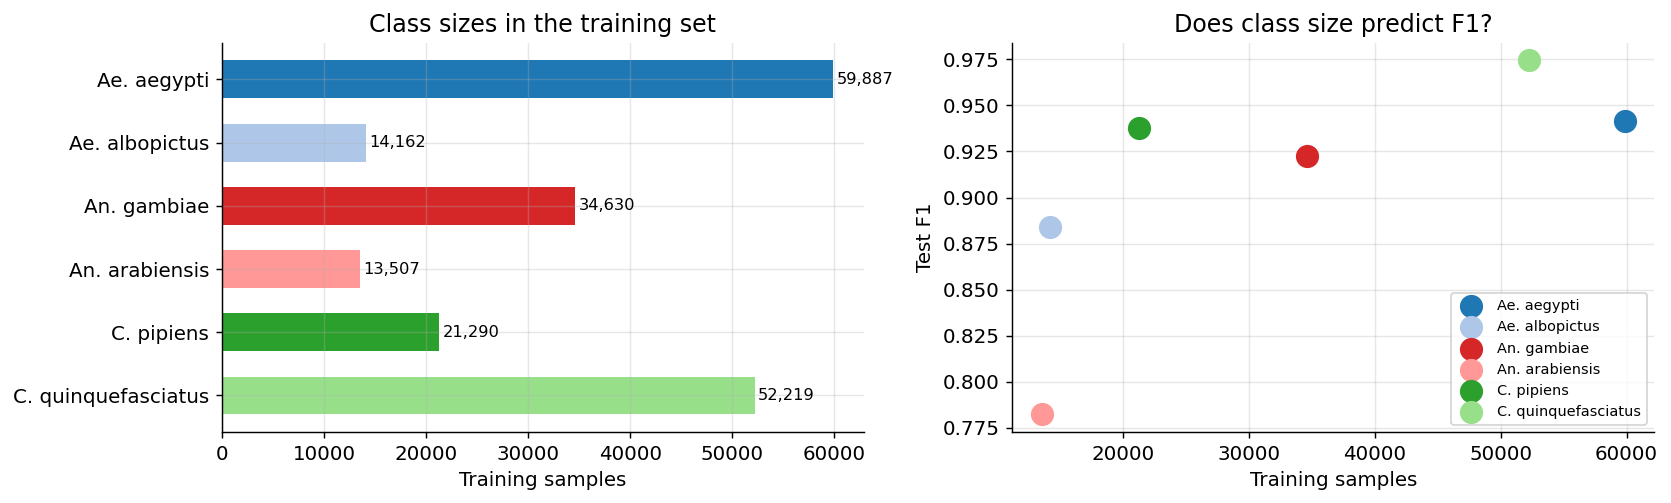

            species  train_n       f1
        Ae. aegypti    59887 0.941492
     Ae. albopictus    14162 0.884091
        An. gambiae    34630 0.922728
     An. arabiensis    13507 0.782250
         C. pipiens    21290 0.937797
C. quinquefasciatus    52219 0.974405


In [35]:
with open(METADATA) as f:
    meta = json.load(f)
with open(METRICS) as f:
    metrics = json.load(f)

train_counts  = meta['class_counts']['train']
f1_per_class  = {sp: v['f1'] for sp, v in metrics['per_class'].items()}
summary = pd.DataFrame({
    'species': SPECIES_ORDER,
    'train_n': [train_counts[s] for s in SPECIES_ORDER],
    'f1':      [f1_per_class[s] for s in SPECIES_ORDER],
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
bars = ax.barh(summary['species'], summary['train_n'], color=PALETTE, height=0.6)
ax.set_xlabel('Training samples')
ax.set_title('Class sizes in the training set')
ax.invert_yaxis()
for bar, n in zip(bars, summary['train_n']):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2,
            f'{n:,}', va='center', fontsize=9)

ax = axes[1]
for sp, color in SPECIES_COLORS.items():
    row = summary[summary['species'] == sp].iloc[0]
    ax.scatter(row['train_n'], row['f1'], s=140, color=color, zorder=3, label=sp)
ax.set_xlabel('Training samples')
ax.set_ylabel('Test F1')
ax.set_title('Does class size predict F1?')
ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('fig_class_balance.png', bbox_inches='tight')
plt.show()
print(summary.to_string(index=False))

**Finding:** Class imbalance partially explains the gap, but *Ae. albopictus* has similar training size to *An. arabiensis* yet 10 F1 points higher. Something else drives *An. arabiensis* failure — the spectrograms themselves.

## 3. Confusion matrix – which species are mixed up?

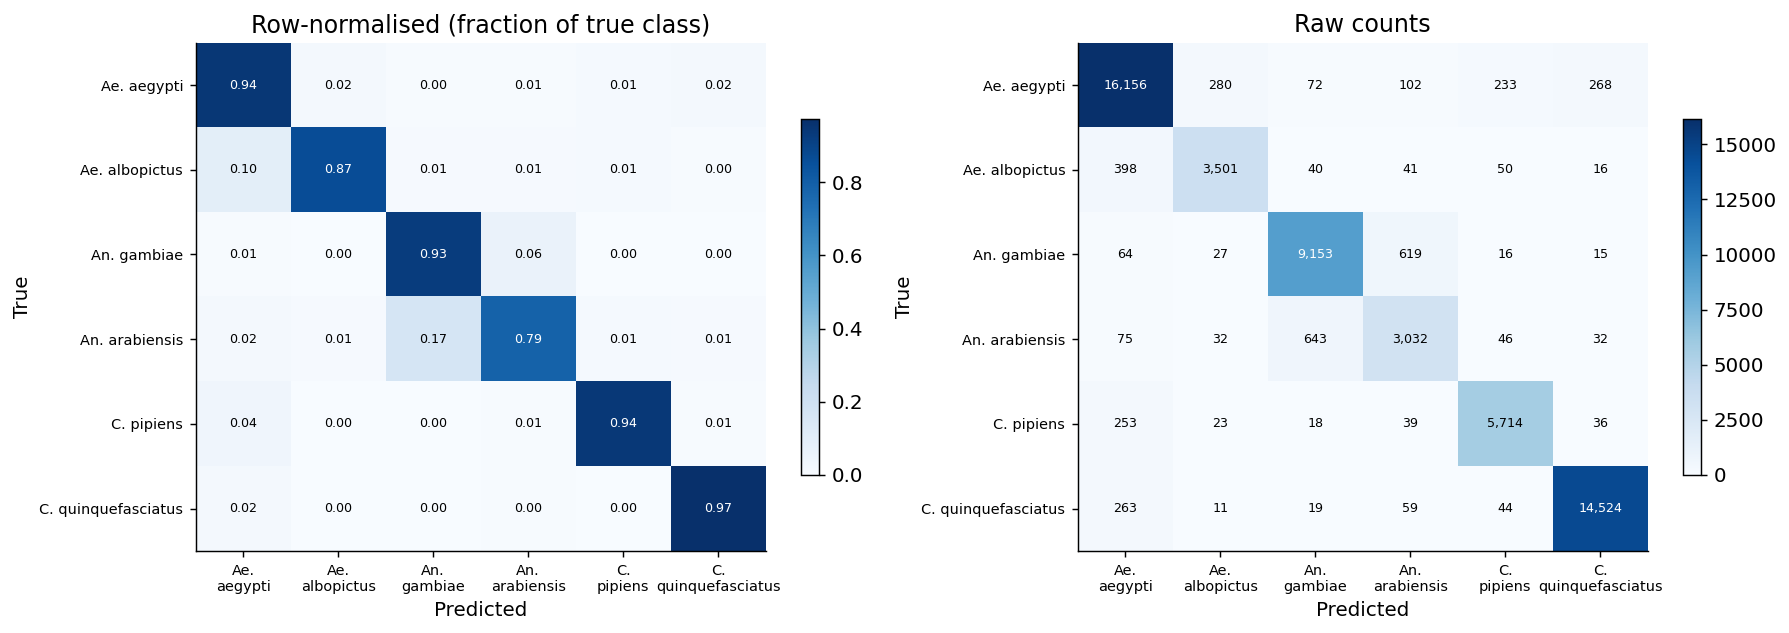

In [36]:
conf_raw  = pd.read_csv(CONFUSION, index_col=0)
conf_raw  = conf_raw.loc[SPECIES_ORDER, SPECIES_ORDER]
conf_norm = conf_raw.div(conf_raw.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, fmt in [
    (axes[0], conf_norm, 'Row-normalised (fraction of true class)', '.2f'),
    (axes[1], conf_raw,  'Raw counts',                              'd'),
]:
    im = ax.imshow(data.values, cmap='Blues', vmin=0, aspect='auto')
    ax.set_xticks(range(len(SPECIES_ORDER)))
    ax.set_yticks(range(len(SPECIES_ORDER)))
    short = [s.replace('. ', '.\n') for s in SPECIES_ORDER]
    ax.set_xticklabels(short, fontsize=8)
    ax.set_yticklabels(SPECIES_ORDER, fontsize=8)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    ax.grid(False)
    for i in range(len(SPECIES_ORDER)):
        for j in range(len(SPECIES_ORDER)):
            v = data.values[i, j]
            text = f'{v:{fmt}}' if fmt == '.2f' else f'{int(v):,}'
            ax.text(j, i, text, ha='center', va='center', fontsize=7,
                    color='white' if v > data.values.max() * 0.5 else 'black')
    plt.colorbar(im, ax=ax, shrink=0.7)

plt.tight_layout()
plt.savefig('fig_confusion.png', bbox_inches='tight')
plt.show()

**Key finding:** *An. gambiae* ↔ *An. arabiensis* confusion is the dominant error. It is **asymmetric**: 16.7% of *An. arabiensis* samples are labelled as *An. gambiae*, but only 6.3% in the other direction. These are biologically closely related sibling species with nearly identical wingbeat morphology.

## 4. Confidence – is the model overconfident on its errors?

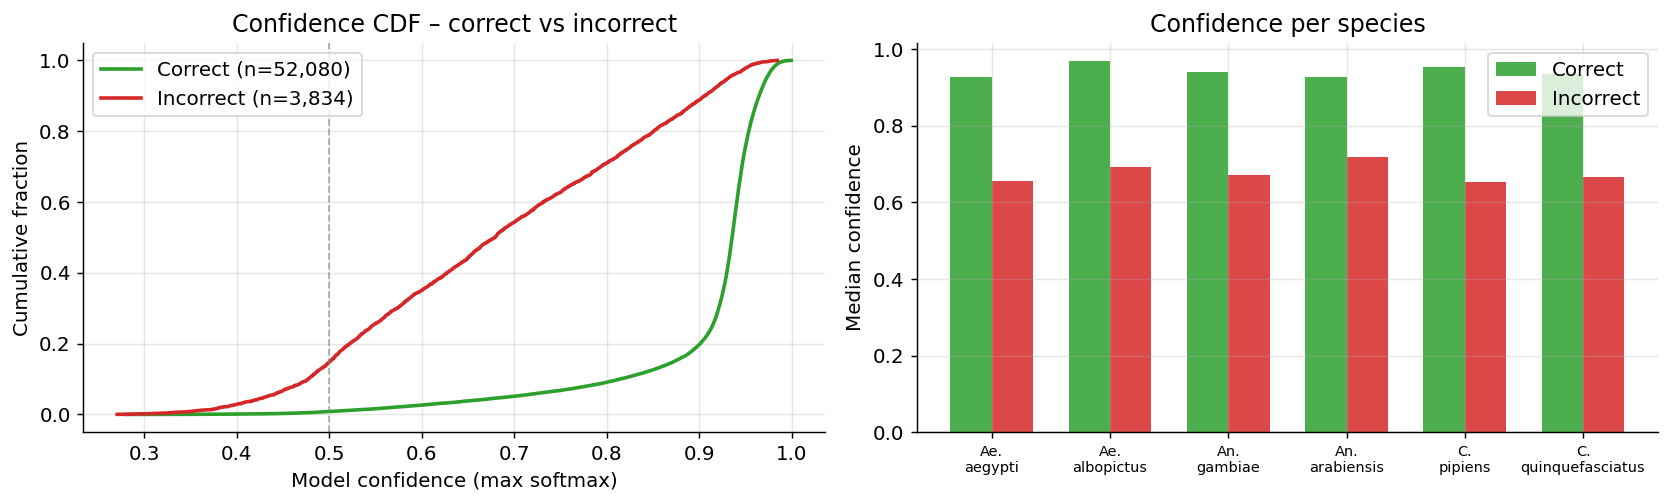

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
for label, color, subset in [
    ('Correct',   '#2ca02c', df[df['correct']]),
    ('Incorrect', '#d62728', df[~df['correct']]),
]:
    vals = np.sort(subset['confidence'].values)
    cdf  = np.arange(1, len(vals)+1) / len(vals)
    ax.plot(vals, cdf, color=color, lw=2, label=f'{label} (n={len(vals):,})')
ax.set_xlabel('Model confidence (max softmax)')
ax.set_ylabel('Cumulative fraction')
ax.set_title('Confidence CDF – correct vs incorrect')
ax.axvline(0.5, color='gray', lw=1, ls='--', alpha=0.6)
ax.legend()

ax = axes[1]
stats = df.groupby(['true_species', 'correct'])['confidence'].median().unstack()
stats = stats.reindex(SPECIES_ORDER)
x = np.arange(len(SPECIES_ORDER))
w = 0.35
ax.bar(x - w/2, stats[True],  width=w, color='#2ca02c', alpha=0.85, label='Correct')
ax.bar(x + w/2, stats[False], width=w, color='#d62728', alpha=0.85, label='Incorrect')
ax.set_xticks(x)
ax.set_xticklabels([s.replace('. ', '.\n') for s in SPECIES_ORDER], fontsize=8)
ax.set_ylabel('Median confidence')
ax.set_title('Confidence per species')
ax.legend()

plt.tight_layout()
plt.savefig('fig_confidence.png', bbox_inches='tight')
plt.show()

**Finding:** The model is overconfident on wrong predictions. Median confidence for incorrect *An. gambiae* predictions is around 0.6–0.7 — meaning it is convinced it is right even when it is not. This is dangerous in a deployment context (e.g., disease-vector monitoring) because a high-confidence error looks identical to a high-confidence correct prediction.

## 5. Wingbeat frequency distributions

`spectral_peak_hz` is the dominant FFT bin of the raw audio (note: not guaranteed to be the fundamental; it reflects the strongest harmonic). It is a proxy for where in the spectrogram the main energy sits.

If two species have overlapping distributions, their spectrograms look alike.

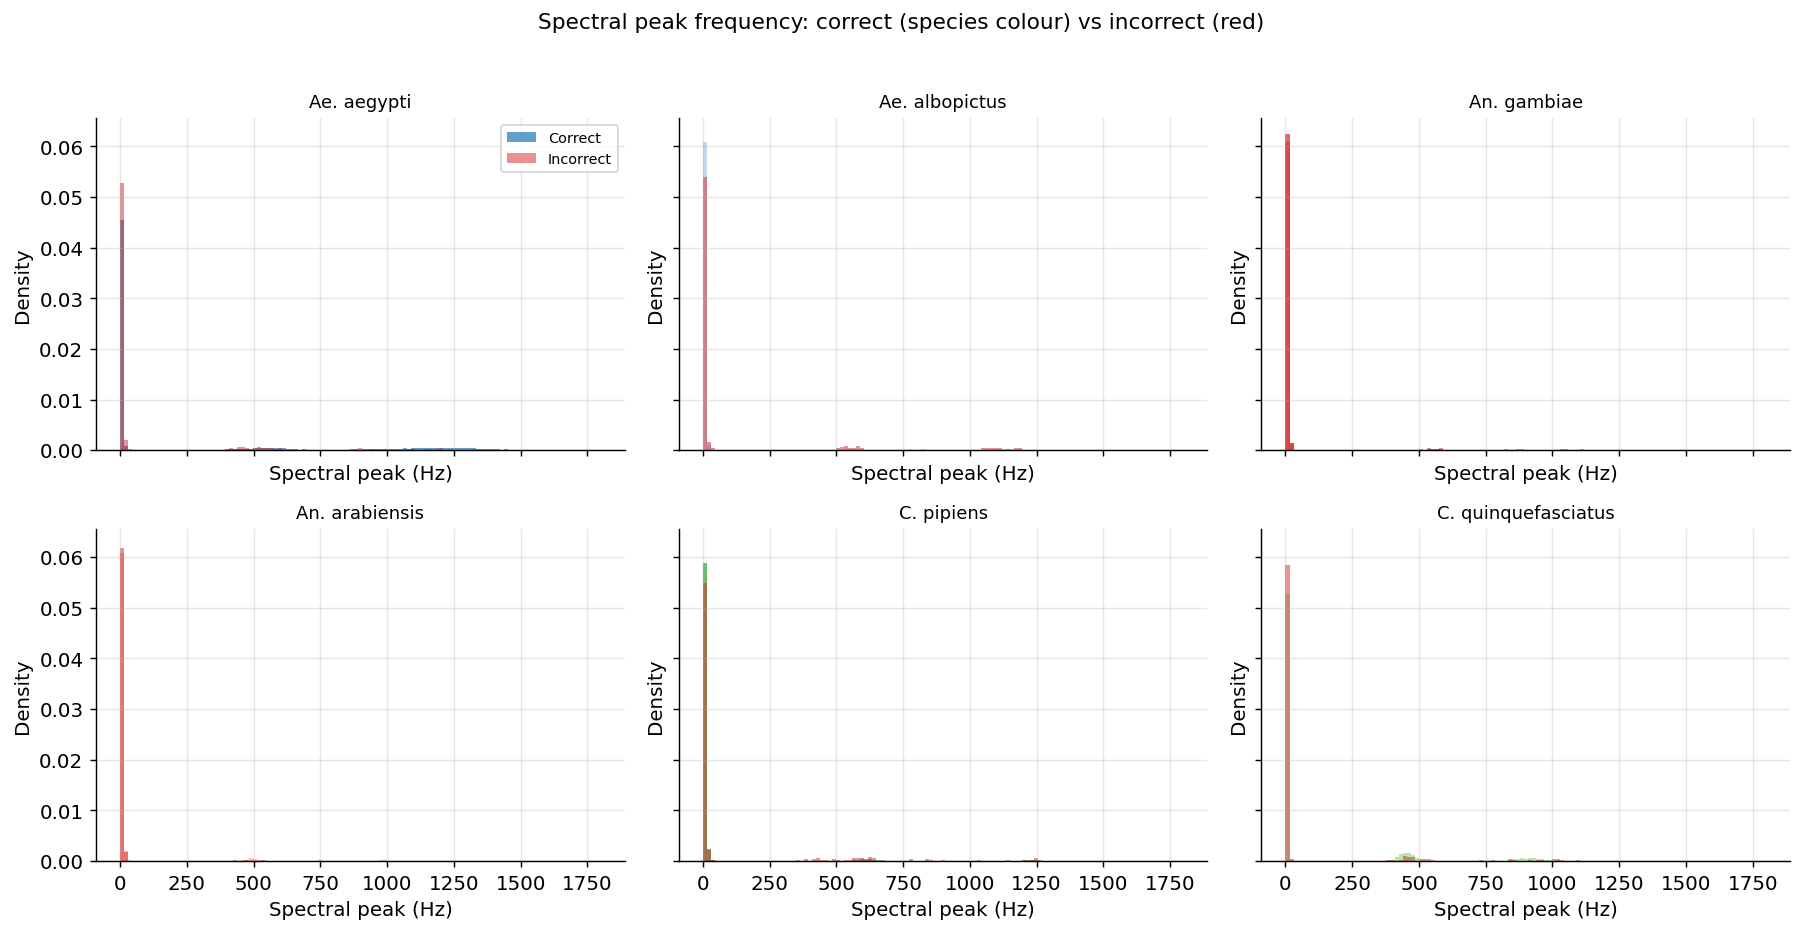

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
axes_flat = axes.flatten()
bins = np.linspace(0, 1800, 120)

for ax, sp in zip(axes_flat, SPECIES_ORDER):
    subset    = df[df['true_species'] == sp]
    correct   = subset[subset['correct']]['spectral_peak_hz']
    incorrect = subset[~subset['correct']]['spectral_peak_hz']

    ax.hist(correct,   bins=bins, density=True, color=SPECIES_COLORS[sp], alpha=0.7, label='Correct')
    ax.hist(incorrect, bins=bins, density=True, color='#d62728',           alpha=0.5,
            label='Incorrect', histtype='stepfilled')
    ax.set_title(sp, fontsize=10)
    ax.set_xlabel('Spectral peak (Hz)')
    ax.set_ylabel('Density')

axes_flat[0].legend(fontsize=8)
plt.suptitle('Spectral peak frequency: correct (species colour) vs incorrect (red)',
             y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig('fig_freq_by_species.png', bbox_inches='tight')
plt.show()

## 6. The Anopheles confusion – deep dive

We separate predictions into four outcomes and ask: at which frequencies does confusion peak?

outcome
Correct An. gambiae          9153
Correct An. arabiensis       3032
Confused within Anopheles    1262
Confused with other genus     307


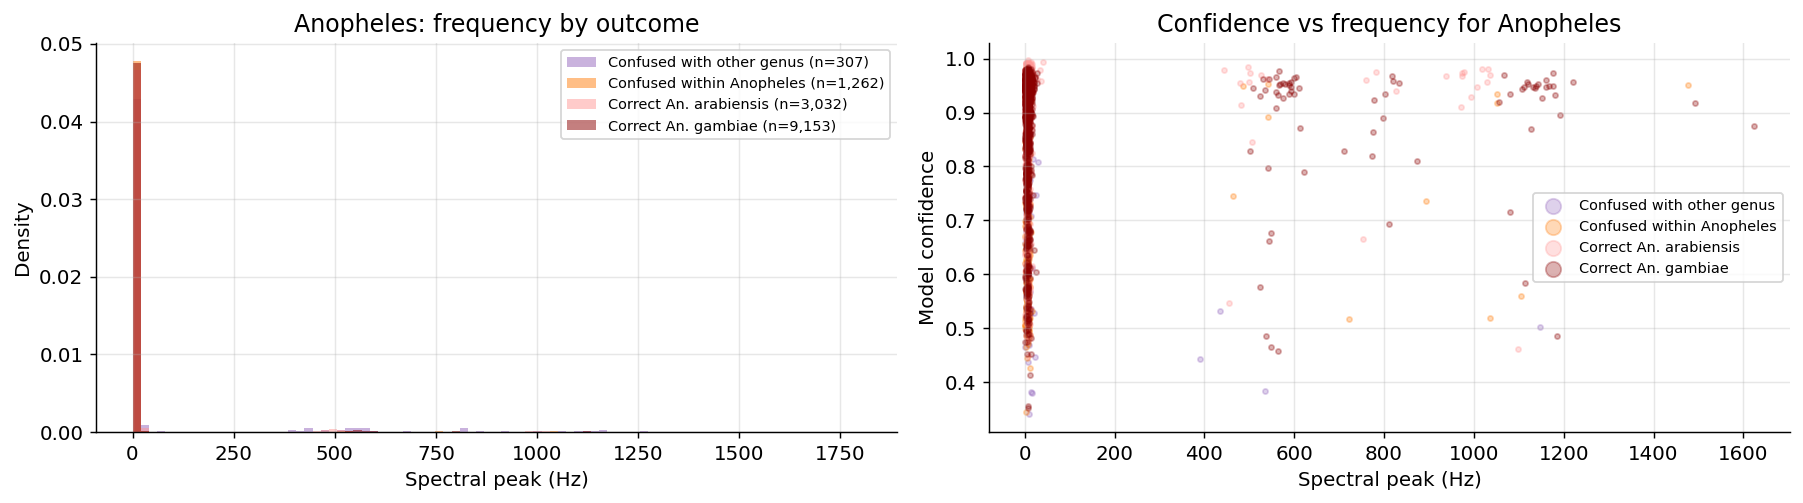

In [39]:
anoph = df[df['true_genus'] == 'Anopheles'].copy()

def outcome_label(row):
    if row['correct']:
        return f"Correct {row['true_species']}"
    elif row['predicted_genus'] == 'Anopheles':
        return 'Confused within Anopheles'
    return 'Confused with other genus'

anoph['outcome'] = anoph.apply(outcome_label, axis=1)
print(anoph['outcome'].value_counts().to_string())

outcome_colors = {
    'Correct An. gambiae':          '#8b0000',
    'Correct An. arabiensis':       '#ff9896',
    'Confused within Anopheles':    '#ff7f0e',
    'Confused with other genus':    '#9467bd',
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
bins2 = np.linspace(0, 1800, 90)
for outcome, grp in anoph.groupby('outcome'):
    ax.hist(grp['spectral_peak_hz'], bins=bins2, density=True, alpha=0.5,
            label=f'{outcome} (n={len(grp):,})',
            color=outcome_colors.get(outcome, 'gray'))
ax.set_xlabel('Spectral peak (Hz)')
ax.set_ylabel('Density')
ax.set_title('Anopheles: frequency by outcome')
ax.legend(fontsize=8)

ax = axes[1]
sample = anoph.sample(min(len(anoph), 3000), random_state=42)
for outcome, grp in sample.groupby('outcome'):
    ax.scatter(grp['spectral_peak_hz'], grp['confidence'],
               s=8, alpha=0.3, color=outcome_colors.get(outcome, 'gray'), label=outcome)
ax.set_xlabel('Spectral peak (Hz)')
ax.set_ylabel('Model confidence')
ax.set_title('Confidence vs frequency for Anopheles')
ax.legend(fontsize=8, markerscale=3)

plt.tight_layout()
plt.savefig('fig_anopheles_deep_dive.png', bbox_inches='tight')
plt.show()

## 7. Per-frequency accuracy in the overlap zone

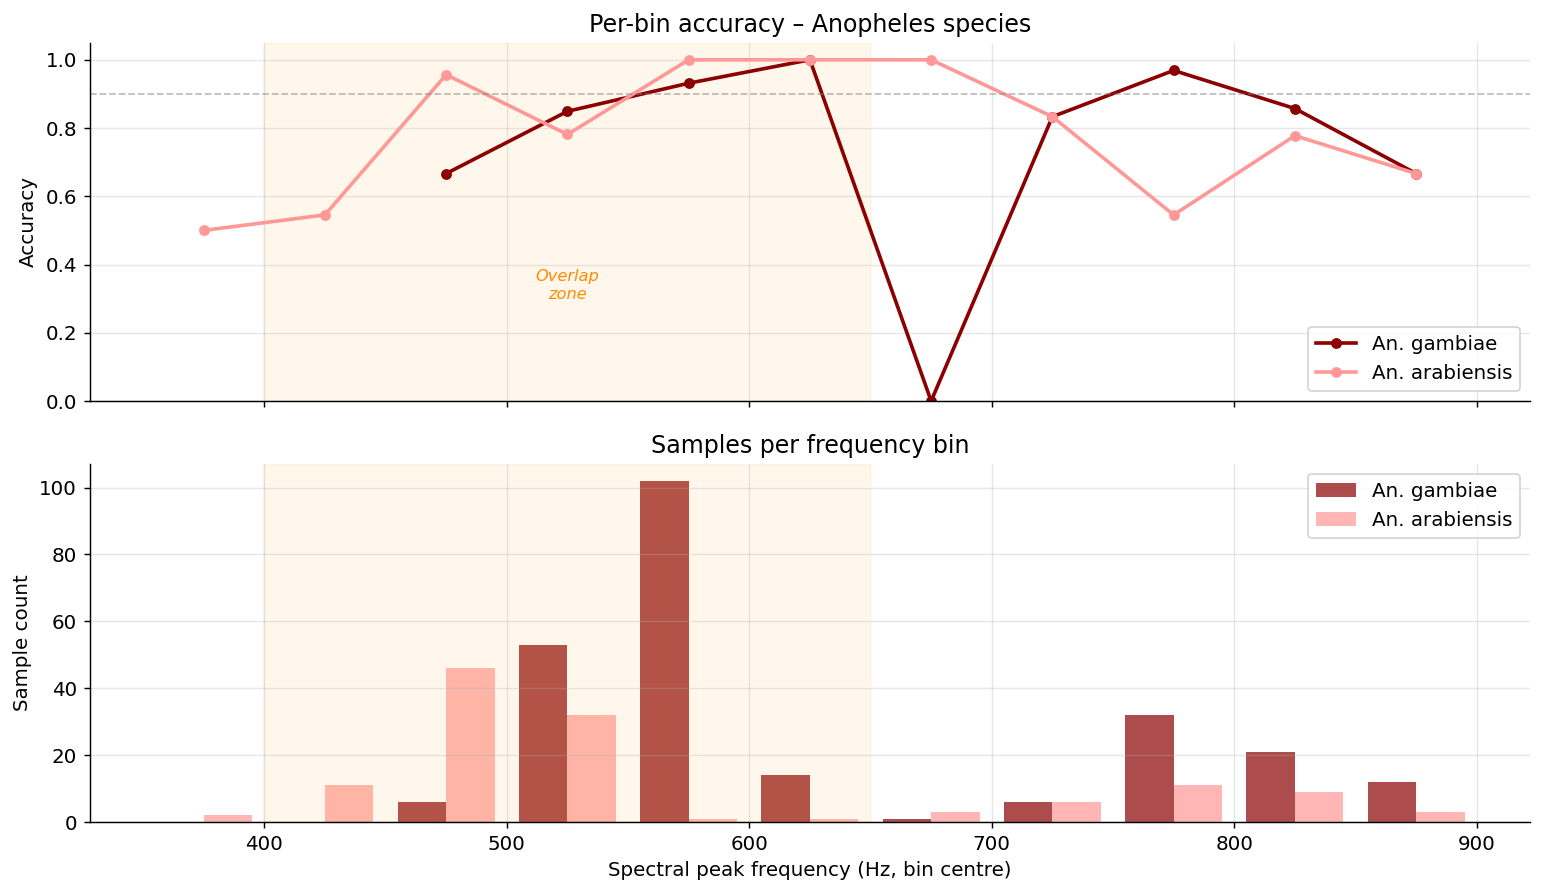

In [40]:
anoph2 = df[df['true_genus'] == 'Anopheles'].copy()
anoph2 = anoph2[anoph2['spectral_peak_hz'].between(200, 900)]

freq_bins = np.arange(200, 901, 50)
anoph2['freq_bin'] = pd.cut(anoph2['spectral_peak_hz'], bins=freq_bins,
                             labels=freq_bins[:-1] + 25).astype(float)

pivot       = anoph2.groupby(['freq_bin', 'true_species'])['correct'].mean().unstack()
count_pivot = anoph2.groupby(['freq_bin', 'true_species']).size().unstack().fillna(0)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax = axes[0]
for sp, color in [('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]:
    if sp in pivot.columns:
        ax.plot(pivot.index, pivot[sp], marker='o', color=color, lw=2, ms=5, label=sp)
ax.axhline(0.9, color='gray', ls='--', lw=1, alpha=0.5)
ax.set_ylabel('Accuracy')
ax.set_title('Per-bin accuracy – Anopheles species')
ax.legend()
ax.set_ylim(0, 1.05)

ax = axes[1]
bar_w = 20
for i, (sp, color) in enumerate([('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]):
    if sp in count_pivot.columns:
        ax.bar(count_pivot.index + (i - 0.5)*bar_w, count_pivot[sp],
               width=bar_w, color=color, alpha=0.7, label=sp)
ax.set_xlabel('Spectral peak frequency (Hz, bin centre)')
ax.set_ylabel('Sample count')
ax.set_title('Samples per frequency bin')
ax.legend()

for ax in axes:
    ax.axvspan(400, 650, alpha=0.08, color='orange')

axes[0].text(525, 0.3, 'Overlap\nzone', ha='center', fontsize=9,
             color='darkorange', style='italic')

plt.tight_layout()
plt.savefig('fig_freq_accuracy.png', bbox_inches='tight')
plt.show()

## 7b. H2 – Do errors cluster where a clip's frequency is atypical for its species?

**Hypothesis:** Each species has a characteristic wingbeat frequency. Clips whose dominant frequency drifts far from their species median are harder to classify — the model's learned template fits poorly.

`spectral_peak_hz` is used as a proxy for the fundamental (caveat: strongest FFT bin, not guaranteed f0).  
Filter: 100–1500 Hz (removes near-zero / nonsense peaks).

Per-species median spectral_peak_hz:
true_species
Ae. aegypti            1043.1
Ae. albopictus          941.5
An. gambiae             710.8
An. arabiensis          541.5
C. pipiens              641.5
C. quinquefasciatus     478.5


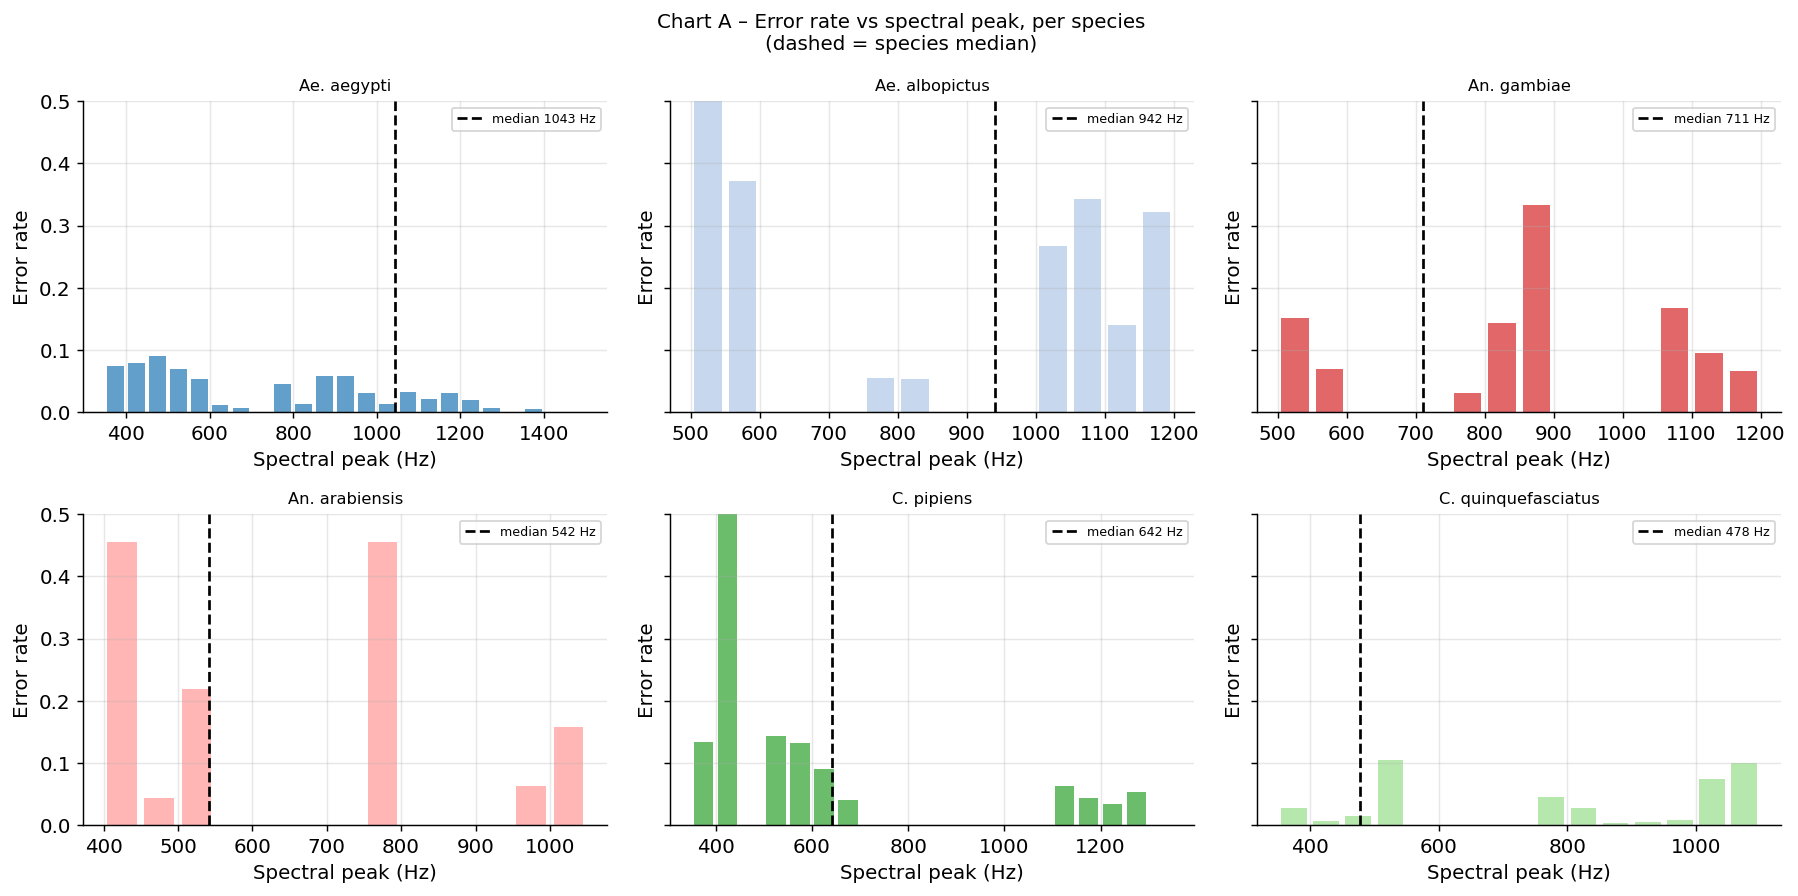

In [41]:
# ── Setup: filter & compute atypicality ─────────────────────────────────────
h2 = df[df['spectral_peak_hz'].between(100, 1500)].copy()

species_median = h2.groupby('true_species')['spectral_peak_hz'].median()
h2['sp_median']  = h2['true_species'].map(species_median)
h2['delta_hz']   = h2['spectral_peak_hz'] - h2['sp_median']
h2['abs_delta']  = h2['delta_hz'].abs()

print("Per-species median spectral_peak_hz:")
print(species_median.reindex(SPECIES_ORDER).round(1).to_string())

# ── Chart A: error rate vs spectral_peak_hz per species ──────────────────────
BIN_W = 50   # Hz per bin
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)

for ax, sp in zip(axes.flatten(), SPECIES_ORDER):
    sub    = h2[h2['true_species'] == sp].copy()
    lo     = (sub['spectral_peak_hz'].min() // BIN_W) * BIN_W
    hi     = (sub['spectral_peak_hz'].max() // BIN_W + 1) * BIN_W
    edges  = np.arange(lo, hi + BIN_W, BIN_W)
    labels = edges[:-1] + BIN_W / 2

    sub['bin'] = pd.cut(sub['spectral_peak_hz'], bins=edges, labels=labels).astype(float)
    agg = sub.groupby('bin').agg(err_rate=('correct', lambda x: 1 - x.mean()),
                                  n=('correct', 'size')).reset_index()
    agg = agg[agg['n'] >= 10]   # skip near-empty bins

    color = SPECIES_COLORS[sp]
    ax.bar(agg['bin'], agg['err_rate'], width=BIN_W * 0.8, color=color, alpha=0.7)
    ax.axvline(species_median[sp], color='black', lw=1.5, ls='--', label=f'median {species_median[sp]:.0f} Hz')
    ax.set_title(sp, fontsize=9)
    ax.set_xlabel('Spectral peak (Hz)')
    ax.set_ylabel('Error rate')
    ax.set_ylim(0, 0.5)
    ax.legend(fontsize=7)

plt.suptitle('Chart A – Error rate vs spectral peak, per species\n(dashed = species median)', fontsize=11)
plt.tight_layout()
plt.savefig('fig_h2_error_vs_f0.png', bbox_inches='tight')
plt.show()

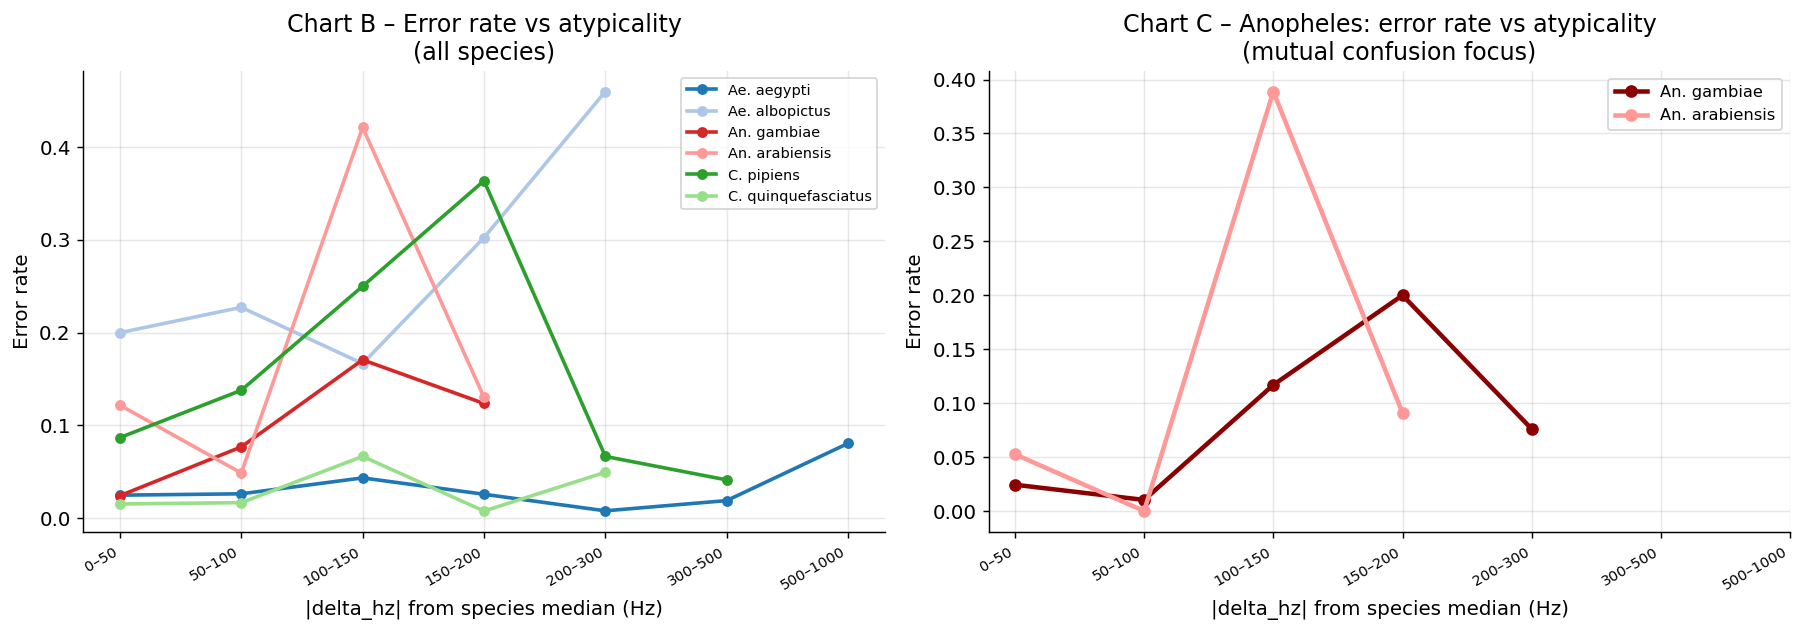


H2 stats – typical (bottom 50% |delta|) vs atypical (top 50% |delta|):
            species  median_peak_hz  typical_err  atypical_err  lift
        Ae. aegypti          1043.0        0.026         0.038  1.46
     Ae. albopictus           942.0        0.200         0.406  2.03
        An. gambiae           711.0        0.073         0.153  2.08
     An. arabiensis           542.0        0.125         0.241  1.93
         C. pipiens           642.0        0.100         0.127  1.28
C. quinquefasciatus           478.0        0.015         0.015  0.99

lift = atypical_err / typical_err  (>1 supports H2)


In [42]:
# ── Chart B: error rate vs |delta_hz| (atypicality), one curve per species ───
DELTA_EDGES = [0, 50, 100, 150, 200, 300, 500, 1000]
delta_labels = [f'{DELTA_EDGES[i]}–{DELTA_EDGES[i+1]}' for i in range(len(DELTA_EDGES)-1)]

h2['delta_bin'] = pd.cut(h2['abs_delta'], bins=DELTA_EDGES, labels=delta_labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for sp in SPECIES_ORDER:
    sub = h2[h2['true_species'] == sp]
    agg = sub.groupby('delta_bin', observed=True).agg(
        err_rate=('correct', lambda x: 1 - x.mean()),
        n=('correct', 'size')
    )
    agg = agg[agg['n'] >= 15]
    ax.plot(range(len(agg)), agg['err_rate'], marker='o', ms=5,
            color=SPECIES_COLORS[sp], lw=2, label=sp)

ax.set_xticks(range(len(delta_labels)))
ax.set_xticklabels(delta_labels, rotation=30, ha='right', fontsize=8)
ax.set_xlabel('|delta_hz| from species median (Hz)')
ax.set_ylabel('Error rate')
ax.set_title('Chart B – Error rate vs atypicality\n(all species)')
ax.legend(fontsize=8)

# ── Chart C: Anopheles only, restricted to mutual confusions ─────────────────
ax = axes[1]
anoph_mutual = h2[
    h2['true_species'].isin(['An. gambiae', 'An. arabiensis']) &
    (
        (h2['true_species'].eq('An. gambiae')    & (h2['predicted_species'].eq('An. arabiensis') | h2['correct'])) |
        (h2['true_species'].eq('An. arabiensis') & (h2['predicted_species'].eq('An. gambiae')    | h2['correct']))
    )
].copy()

for sp, color in [('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]:
    sub = anoph_mutual[anoph_mutual['true_species'] == sp]
    # error here = predicted as the sibling (or any wrong)
    sub = sub.copy()
    sub['is_error'] = ~sub['correct']
    agg = sub.groupby('delta_bin', observed=True).agg(
        err_rate=('is_error', 'mean'),
        n=('is_error', 'size')
    )
    agg = agg[agg['n'] >= 10]
    ax.plot(range(len(agg)), agg['err_rate'], marker='o', ms=6,
            color=color, lw=2.5, label=sp)

ax.set_xticks(range(len(delta_labels)))
ax.set_xticklabels(delta_labels, rotation=30, ha='right', fontsize=8)
ax.set_xlabel('|delta_hz| from species median (Hz)')
ax.set_ylabel('Error rate')
ax.set_title('Chart C – Anopheles: error rate vs atypicality\n(mutual confusion focus)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig_h2_error_vs_atypicality.png', bbox_inches='tight')
plt.show()

# ── Stats table: typical (bottom 50% |delta|) vs atypical (top 50%) ──────────
rows = []
for sp in SPECIES_ORDER:
    sub     = h2[h2['true_species'] == sp]
    thresh  = sub['abs_delta'].median()
    typical = sub[sub['abs_delta'] <= thresh]
    atypic  = sub[sub['abs_delta'] >  thresh]
    rows.append({
        'species':         sp,
        'median_peak_hz':  round(species_median[sp], 0),
        'typical_err':     round(1 - typical['correct'].mean(), 3),
        'atypical_err':    round(1 - atypic['correct'].mean(), 3),
        'lift':            round((1 - atypic['correct'].mean()) / max(1 - typical['correct'].mean(), 1e-6), 2),
    })

stats_table = pd.DataFrame(rows)
print("\nH2 stats – typical (bottom 50% |delta|) vs atypical (top 50% |delta|):")
print(stats_table.to_string(index=False))
print("\nlift = atypical_err / typical_err  (>1 supports H2)")

**H2 finding (run the cell above to confirm):**  
Look at the `lift` column — if consistently >1 across species, H2 is supported (atypical clips are harder).  
For the *Anopheles* pair specifically (Chart C): if the error curve rises with `|delta_hz|`, the model struggles most when a clip's frequency drifts away from that species' own centre — i.e., toward the sibling species' range.  
If the curves are flat, H2 is not the driver; consider H6 (event duration) or H7 (background noise level using `raw_rms`) next.

## 8. Real spectrogram analysis

We read WAV files directly from `archive.zip` (no extraction needed) and compute log-Mel spectrograms using the **exact same pipeline as the trained model**.

For each species we show correctly classified samples. Then we zoom into the *Anopheles* confusion: placing a confused sample next to a correctly classified one at the same frequency to see what the model could not distinguish.

In [43]:
import zipfile, io
from math import gcd
from pathlib import Path

import numpy as np
import soundfile as sf
from scipy.signal import stft

# ── archive.zip lives next to the repo (workspace root) ────────────────
ZIP_PATH = Path(r'D:\AI and Vis\archive.zip')
print(f"ZIP_PATH: {ZIP_PATH}")
print(f"ZIP_PATH exists: {ZIP_PATH.exists()}")

# ── Audio / spectrogram parameters (must match the trained model exactly) ────
SR, N_FFT, HOP, N_MELS = 8000, 512, 32, 128
F_MIN, F_MAX, TOP_DB    = 0.0, 4000.0, 80.0
N_SAMPLES               = round(SR * 0.65)   # 5200

def hz_to_mel(hz):  return 2595 * np.log10(1 + hz / 700)
def mel_to_hz(mel): return 700 * (10 ** (mel / 2595) - 1)

def _build_mel_fb():
    mel_pts = np.linspace(hz_to_mel(F_MIN), hz_to_mel(F_MAX), N_MELS + 2)
    hz_pts  = mel_to_hz(mel_pts)
    bins    = np.floor((N_FFT + 1) * hz_pts / SR).astype(int)
    fb      = np.zeros((N_MELS, N_FFT // 2 + 1))
    for m in range(1, N_MELS + 1):
        lo, mid, hi = bins[m-1], bins[m], bins[m+1]
        for k in range(lo, mid):
            if mid > lo: fb[m-1, k] = (k - lo) / (mid - lo)
        for k in range(mid, hi):
            if hi  > mid: fb[m-1, k] = (hi - k) / (hi - mid)
    return fb

MEL_FB = _build_mel_fb()

def compute_logmel(signal):
    signal = np.asarray(signal, dtype=np.float32)
    signal = signal - signal.mean()
    _, _, Zxx = stft(signal, fs=SR, nperseg=N_FFT, noverlap=N_FFT - HOP, window='hann')
    mel_s   = MEL_FB @ np.abs(Zxx) ** 2
    log_mel = 10 * np.log10(np.maximum(mel_s, 1e-10))
    return np.maximum(log_mel, log_mel.max() - TOP_DB)

def load_wav_from_zip(zf, relative_path):
    data  = zf.read(relative_path)
    audio, orig_sr = sf.read(io.BytesIO(data), dtype='float32', always_2d=True)
    mono = audio.mean(axis=1)
    if orig_sr != SR:
        from scipy.signal import resample_poly
        d = gcd(orig_sr, SR)
        mono = resample_poly(mono, SR // d, orig_sr // d).astype(np.float32)
    n = N_SAMPLES
    if len(mono) > n:
        start = (len(mono) - n) // 2
        mono  = mono[start:start + n]
    elif len(mono) < n:
        left = (n - len(mono)) // 2
        mono = np.pad(mono, (left, n - len(mono) - left))
    return mono.astype(np.float32)

print(f"Mel filterbank shape: {MEL_FB.shape}")

ZIP_PATH: D:\AI and Vis\archive.zip
ZIP_PATH exists: True
Mel filterbank shape: (128, 257)


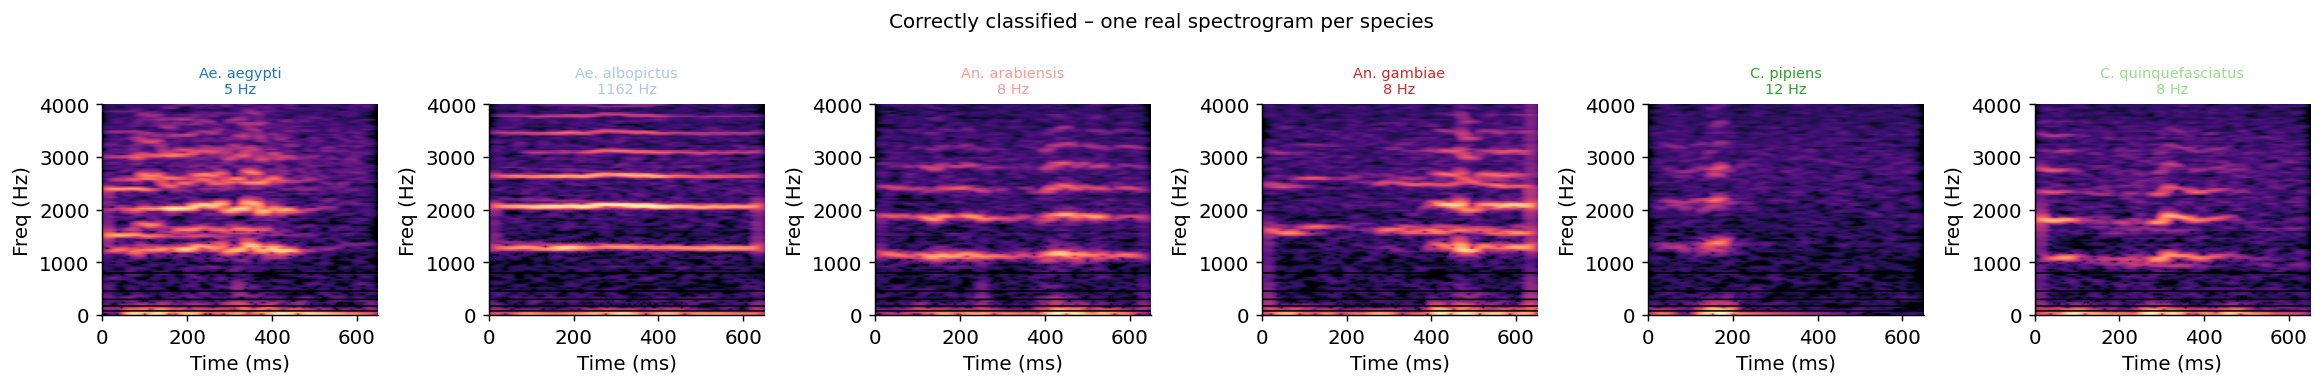

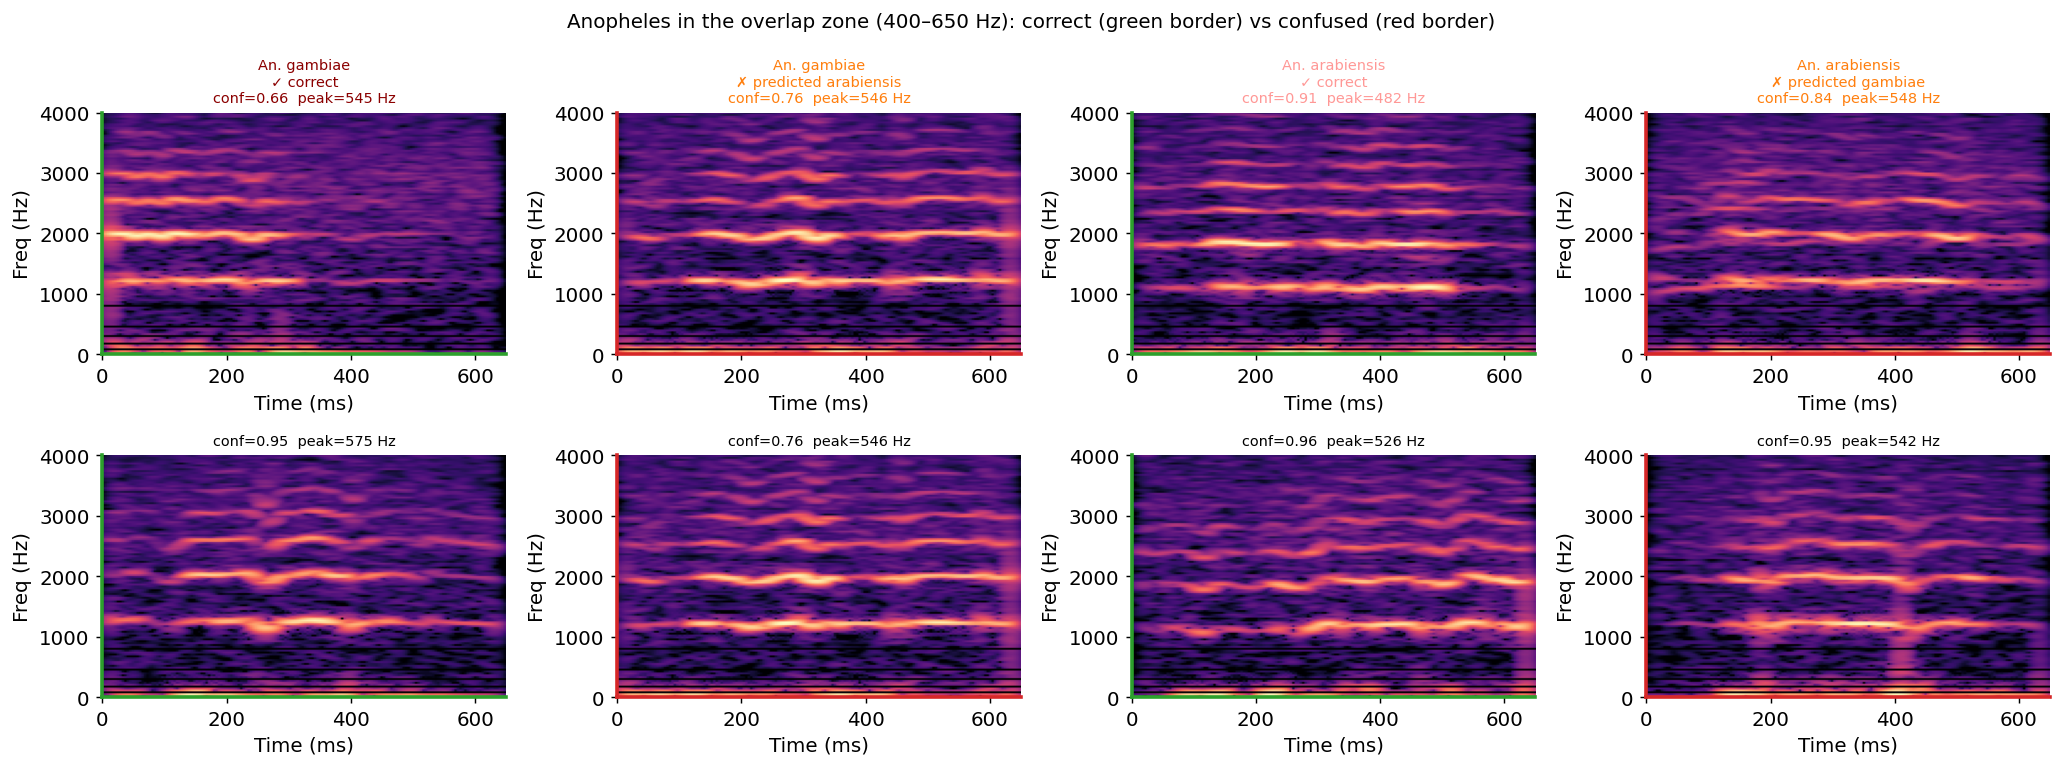

In [44]:
# ── 8a. One representative correct spectrogram per species ───────────────────
N_PER_SPECIES = 1   # increase if you want more examples

sample_rows = (
    df[df['correct']]
    .groupby('true_species', group_keys=False)
    .apply(lambda g: g.sample(N_PER_SPECIES, random_state=42))
)

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for ax, (_, row) in zip(axes, sample_rows.iterrows()):
        sig  = load_wav_from_zip(zf, row['relative_path'])
        spec = compute_logmel(sig)
        ax.imshow(spec, origin='lower', aspect='auto', cmap='magma',
                  extent=[0, 650, F_MIN, F_MAX])
        ax.set_title(f"{row['true_species']}\n{row['spectral_peak_hz']:.0f} Hz",
                     fontsize=8, color=SPECIES_COLORS[row['true_species']])
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel('Freq (Hz)')
        ax.grid(False)

plt.suptitle('Correctly classified – one real spectrogram per species', fontsize=11)
plt.tight_layout()
plt.savefig('fig_real_spectrograms_correct.png', bbox_inches='tight')
plt.show()

# ── 8b. Anopheles confusion: correct vs confused side-by-side ────────────────
# Pick samples in the overlap zone (400–650 Hz) for maximum visual impact
overlap_mask = df['spectral_peak_hz'].between(400, 650)

anoph_correct_gam = df[df['true_species'].eq('An. gambiae')   & df['correct'] & overlap_mask]
anoph_correct_ara = df[df['true_species'].eq('An. arabiensis') & df['correct'] & overlap_mask]
anoph_wrong_ara   = df[df['true_species'].eq('An. arabiensis') & ~df['correct']
                       & df['predicted_species'].eq('An. gambiae') & overlap_mask]
anoph_wrong_gam   = df[df['true_species'].eq('An. gambiae')   & ~df['correct']
                       & df['predicted_species'].eq('An. arabiensis') & overlap_mask]

picks = [
    (anoph_correct_gam, 'An. gambiae\n✓ correct',         '#8b0000'),
    (anoph_wrong_gam,   'An. gambiae\n✗ predicted arabiensis', '#ff7f0e'),
    (anoph_correct_ara, 'An. arabiensis\n✓ correct',       '#ff9896'),
    (anoph_wrong_ara,   'An. arabiensis\n✗ predicted gambiae',  '#ff7f0e'),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for col, (pool, label, color) in enumerate(picks):
        for row_idx in range(2):
            ax   = axes[row_idx][col]
            row  = pool.sample(1, random_state=row_idx * 7 + col).iloc[0]
            sig  = load_wav_from_zip(zf, row['relative_path'])
            spec = compute_logmel(sig)
            ax.imshow(spec, origin='lower', aspect='auto', cmap='magma',
                      extent=[0, 650, F_MIN, F_MAX])
            if row_idx == 0:
                ax.set_title(f'{label}\nconf={row["confidence"]:.2f}  peak={row["spectral_peak_hz"]:.0f} Hz',
                             fontsize=8, color=color)
            else:
                ax.set_title(f'conf={row["confidence"]:.2f}  peak={row["spectral_peak_hz"]:.0f} Hz',
                             fontsize=8)
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel('Freq (Hz)')
            ax.grid(False)
            border_color = '#d62728' if '✗' in label else '#2ca02c'
            for spine in ax.spines.values():
                spine.set_edgecolor(border_color)
                spine.set_linewidth(2)

plt.suptitle('Anopheles in the overlap zone (400–650 Hz): correct (green border) vs confused (red border)',
             fontsize=11)
plt.tight_layout()
plt.savefig('fig_anopheles_spectrograms.png', bbox_inches='tight')
plt.show()

## 8b. Listen – can you hear the difference?

Play the samples below. If you cannot reliably tell *An. gambiae* from *An. arabiensis* by ear, the model's confusion is acoustically justified.

In [45]:
from IPython.display import Audio, display

overlap_mask = df['spectral_peak_hz'].between(400, 650)

listen_cases = {
    'An. gambiae   – CORRECT (overlap zone)':       df[df['true_species'].eq('An. gambiae')    & df['correct']  & overlap_mask],
    'An. gambiae   – WRONG → predicted arabiensis': df[df['true_species'].eq('An. gambiae')    & ~df['correct'] & df['predicted_species'].eq('An. arabiensis') & overlap_mask],
    'An. arabiensis – CORRECT (overlap zone)':      df[df['true_species'].eq('An. arabiensis') & df['correct']  & overlap_mask],
    'An. arabiensis – WRONG → predicted gambiae':   df[df['true_species'].eq('An. arabiensis') & ~df['correct'] & df['predicted_species'].eq('An. gambiae')    & overlap_mask],
}

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for label, pool in listen_cases.items():
        row = pool.sample(1, random_state=99).iloc[0]
        sig = load_wav_from_zip(zf, row['relative_path'])
        print(f"\n{label}")
        print(f"  peak={row['spectral_peak_hz']:.0f} Hz  conf={row['confidence']:.2f}")
        display(Audio(sig, rate=SR))


An. gambiae   – CORRECT (overlap zone)
  peak=537 Hz  conf=0.73



An. gambiae   – WRONG → predicted arabiensis
  peak=537 Hz  conf=0.76



An. arabiensis – CORRECT (overlap zone)
  peak=500 Hz  conf=0.87



An. arabiensis – WRONG → predicted gambiae
  peak=542 Hz  conf=0.95


## 8c. Average spectrograms & difference maps

Individual samples are noisy. Averaging over hundreds of samples cancels the noise and reveals any **systematic** difference in energy distribution between correct and confused predictions.

Computing average spectrograms...
  An. gambiae correct: 50 samples
  An. gambiae confused: 8 samples
  An. arabiensis correct: 50 samples
  An. arabiensis confused: 4 samples


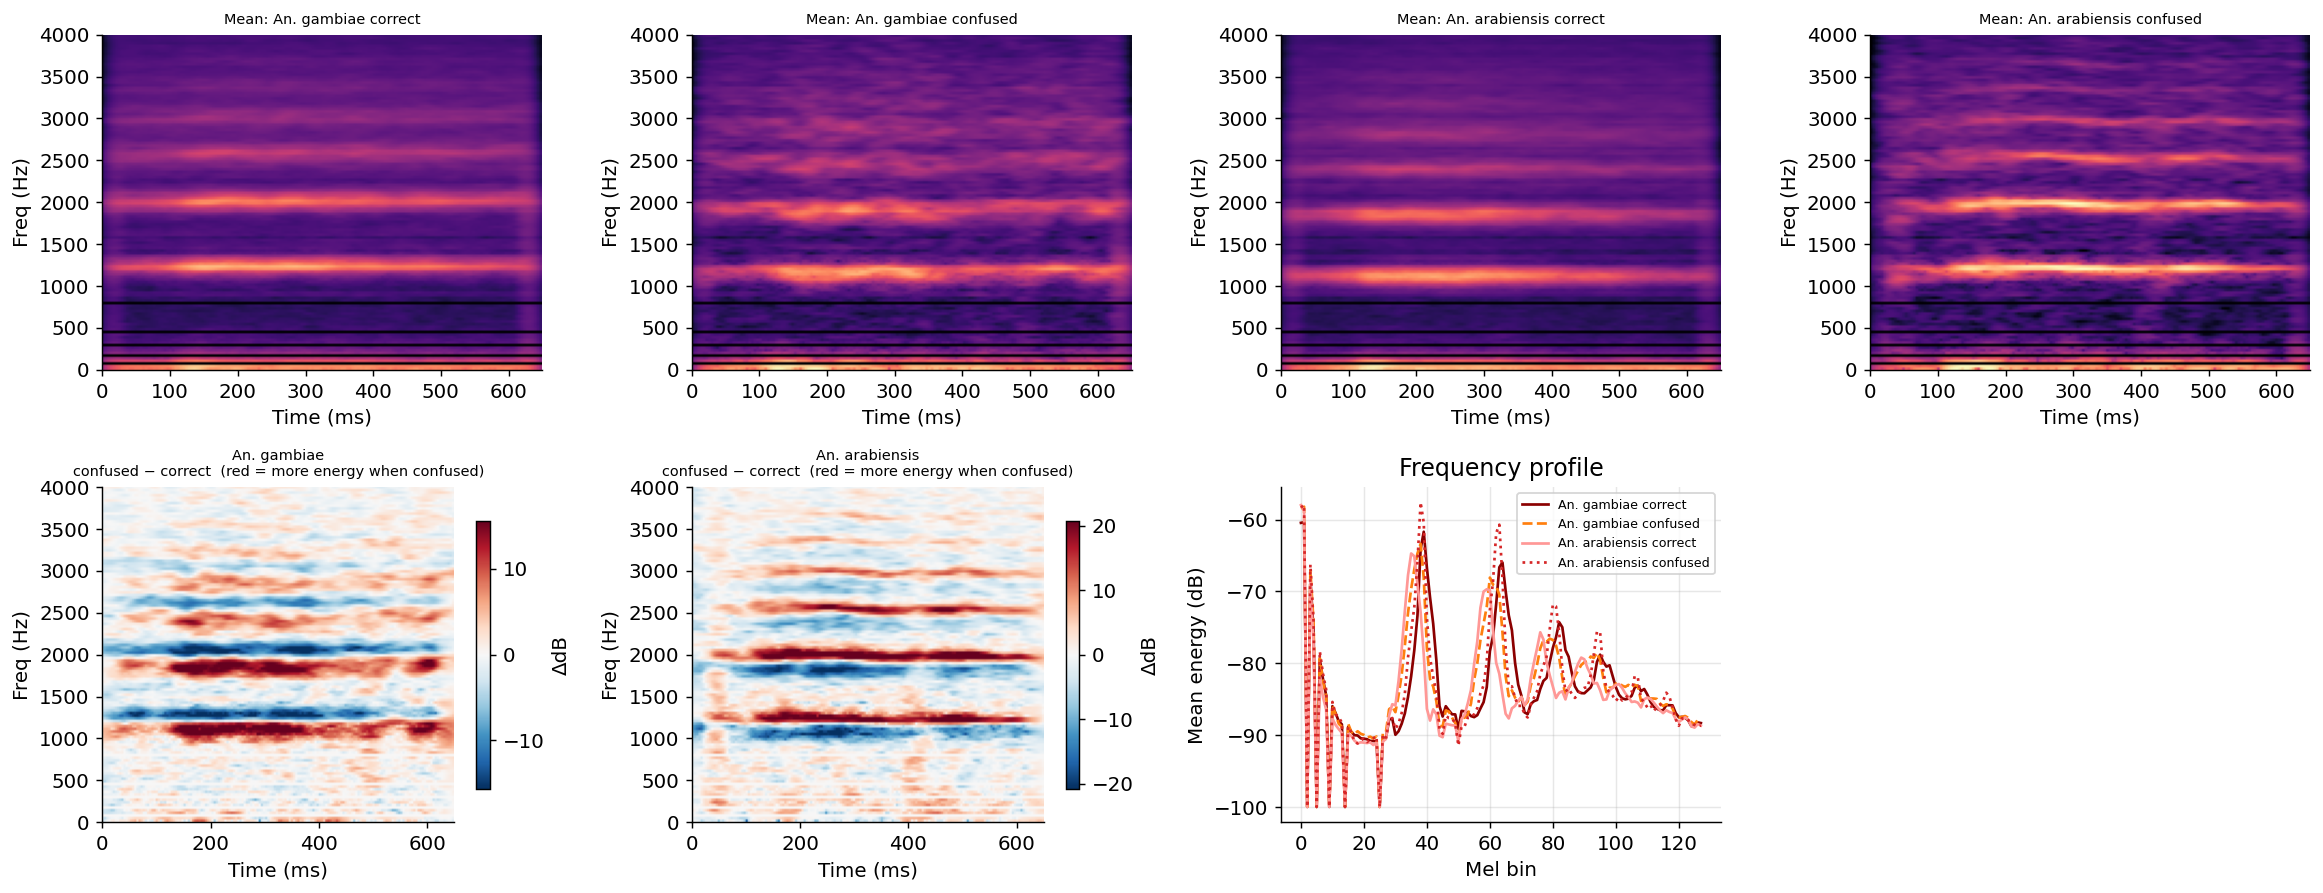

In [46]:
N_AVG = 50   # start small; raise to 300 for final run

categories = {
    'An. gambiae correct':    df[df['true_species'].eq('An. gambiae')    & df['correct']  & overlap_mask],
    'An. gambiae confused':   df[df['true_species'].eq('An. gambiae')    & ~df['correct'] & df['predicted_species'].eq('An. arabiensis') & overlap_mask],
    'An. arabiensis correct': df[df['true_species'].eq('An. arabiensis') & df['correct']  & overlap_mask],
    'An. arabiensis confused':df[df['true_species'].eq('An. arabiensis') & ~df['correct'] & df['predicted_species'].eq('An. gambiae')    & overlap_mask],
}

print("Computing average spectrograms...")
avg_specs = {}
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for label, pool in categories.items():
        rows  = pool.sample(min(N_AVG, len(pool)), random_state=0)
        stack = []
        for _, row in rows.iterrows():
            try:
                sig = load_wav_from_zip(zf, row['relative_path'])
                stack.append(compute_logmel(sig))
            except Exception:
                pass
        avg_specs[label] = np.mean(stack, axis=0)
        print(f"  {label}: {len(stack)} samples")

# ── 4 average spectrograms ───────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
vmin = min(s.min() for s in avg_specs.values())
vmax = max(s.max() for s in avg_specs.values())

for col, label in enumerate(categories):
    ax = axes[0][col]
    ax.imshow(avg_specs[label], origin='lower', aspect='auto', cmap='magma',
              vmin=vmin, vmax=vmax, extent=[0, 650, F_MIN, F_MAX])
    ax.set_title(f'Mean: {label}', fontsize=8)
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Freq (Hz)'); ax.grid(False)

# ── 2 difference maps (confused − correct) ──────────────────────────────────
for col, (sp, c_lbl, w_lbl) in enumerate([
    ('An. gambiae',    'An. gambiae correct',    'An. gambiae confused'),
    ('An. arabiensis', 'An. arabiensis correct', 'An. arabiensis confused'),
]):
    ax   = axes[1][col]
    diff = avg_specs[w_lbl] - avg_specs[c_lbl]
    lim  = np.percentile(np.abs(diff), 98)
    im   = ax.imshow(diff, origin='lower', aspect='auto', cmap='RdBu_r',
                     vmin=-lim, vmax=lim, extent=[0, 650, F_MIN, F_MAX])
    ax.set_title(f'{sp}\nconfused − correct  (red = more energy when confused)', fontsize=8)
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Freq (Hz)'); ax.grid(False)
    plt.colorbar(im, ax=ax, shrink=0.8, label='ΔdB')

# ── frequency profiles ───────────────────────────────────────────────────────
ax = axes[1][2]
styles = [('#8b0000','-'), ('#ff7f0e','--'), ('#ff9896','-'), ('#d62728',':')]
for (label, _), (color, ls) in zip(categories.items(), styles):
    ax.plot(avg_specs[label].mean(axis=1), label=label, color=color, ls=ls, lw=1.5)
ax.set_xlabel('Mel bin'); ax.set_ylabel('Mean energy (dB)')
ax.set_title('Frequency profile'); ax.legend(fontsize=7)

axes[1][3].axis('off')   # spare panel

plt.tight_layout()
plt.savefig('fig_avg_spectrograms.png', bbox_inches='tight')
plt.show()

## 9. Training curve

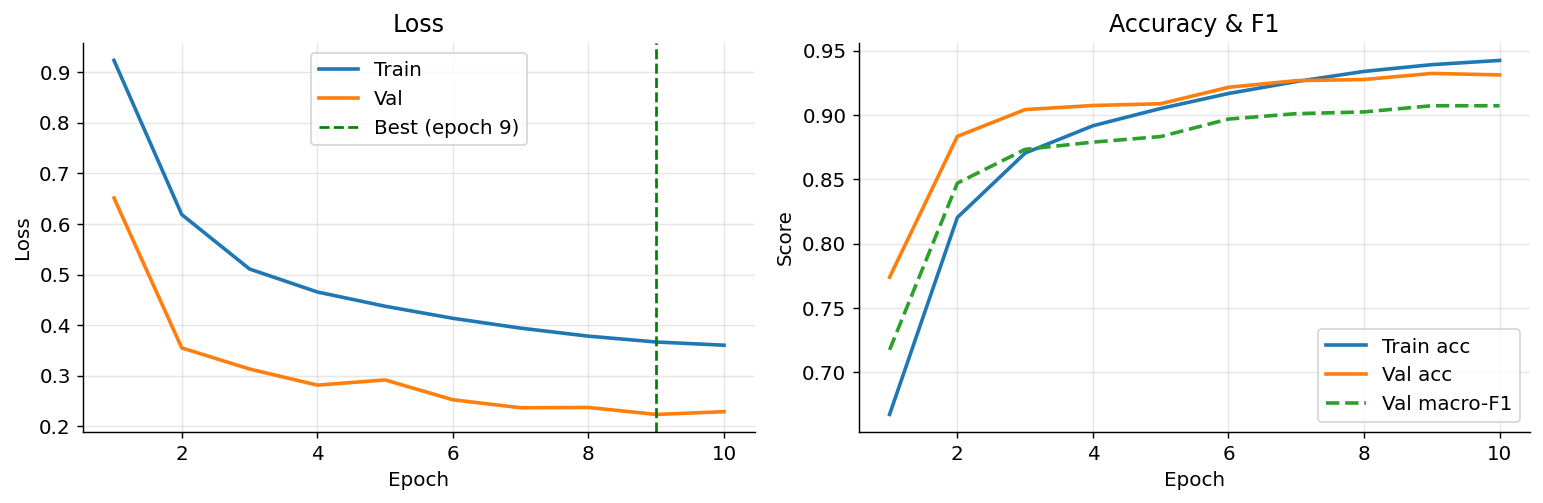

In [47]:
hist = pd.read_csv(HISTORY)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
best_epoch = hist.loc[hist['validation_macro_f1'].idxmax(), 'epoch']

ax = axes[0]
ax.plot(hist['epoch'], hist['train_loss'],      lw=2, color='#1f77b4', label='Train')
ax.plot(hist['epoch'], hist['validation_loss'], lw=2, color='#ff7f0e', label='Val')
ax.axvline(best_epoch, color='green', ls='--', lw=1.5, label=f'Best (epoch {best_epoch})')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.set_title('Loss'); ax.legend()

ax = axes[1]
ax.plot(hist['epoch'], hist['train_accuracy'],      lw=2, color='#1f77b4', label='Train acc')
ax.plot(hist['epoch'], hist['validation_accuracy'], lw=2, color='#ff7f0e', label='Val acc')
ax.plot(hist['epoch'], hist['validation_macro_f1'], lw=2, color='#2ca02c', ls='--', label='Val macro-F1')
ax.set_xlabel('Epoch'); ax.set_ylabel('Score')
ax.set_title('Accuracy & F1'); ax.legend()

plt.tight_layout()
plt.savefig('fig_training_curve.png', bbox_inches='tight')
plt.show()

## 10. Summary of findings

| Finding | Evidence | Implication |
|---|---|---|
| *An. arabiensis* has the lowest F1 (0.782) | Per-class metrics | Further investigation needed |
| *An. gambiae* ↔ *An. arabiensis* confusion dominates errors | Confusion matrix | Species boundary is acoustically weak |
| Confusion is **asymmetric**: 16.7% of *An. arabiensis* → *An. gambiae*, only 6.3% reverse | Confusion matrix | *An. arabiensis* harder to separate |
| Errors are **high-confidence** (model is overconfident) | Confidence CDF | Dangerous in deployment – wrong with certainty |
| Spectral peak Hz **overlaps completely** between the two Anopheles (400–650 Hz) | Frequency histograms | Species requires sub-150 Hz cues the model struggles with |
| Accuracy drops below 80% **inside the overlap zone** for *An. arabiensis* | Per-bin accuracy plot | Sub-cluster worth investigating in Phase II |

### Open questions for Phase II
- Does CBAM attention focus on the **same harmonic lines** for both Anopheles in the overlap zone?
- Are confused samples' internal feature representations actually the same cluster in the penultimate layer?
- Could training with a **paired contrastive loss** on these two species improve separation?